In [134]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn
from sklearn import preprocessing

# Data preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- Bootstrapping (possibly to increase test data as we only have 3 samples)

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [135]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")

dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [136]:
# Handling object datatype
print(dataset.select_dtypes(object)) # ID Column

print("Before: "+str(dataset.select_dtypes(object).shape))

dataset = dataset.drop("ID",axis=1)
print("After: "+str(dataset.select_dtypes(object).shape))


            ID
0    TRG002174
1    TRG002178
2    TRG002204
3    TRG002206
4    TRG002210
..         ...
395  TRG002948
396  TRG002954
397  TRG002958
398  TRG002961
399  TRG002962

[400 rows x 1 columns]
Before: (400, 1)
After: (400, 0)


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but not categorical data (doesn't use classes)


In [137]:
print(dataset.select_dtypes(np.int64))

print("Before: "+str(dataset.select_dtypes(np.int64).shape))

dataset['original_shape_VoxelVolume'] = dataset['original_shape_VoxelVolume'].astype(float)
print("After: "+str(dataset.select_dtypes(np.int64).shape))

     pCR (outcome)  ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  \
0                1   0    0     0                1           3              3   
1                0   1    1     0                0           3              3   
2                1   0    0     0                1           2              1   
3                0   0    0     0                1           3              3   
4                0   1    0     0                0           2              1   
..             ...  ..  ...   ...              ...         ...            ...   
395              0   1    0     1                0           3              2   
396              0   0    0     0                1           3              3   
397              0   0    0     0                1           2              1   
398              0   1    0     0                0           3              3   
399              0   1    0     0                0           2              1   

     HistologyType  LNStatu

### Handling float64 datatype
#### Continuous Features

Nothing specific left, data is all continuous

In [138]:
# Before
dataset.select_dtypes(np.float64)

,RelapseFreeSurvival (outcome),Age,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,144.000000,41.0,0.813912,0.724080,23.781937,32.844370,37.696154,38.626416,34.713110,39.572718,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,142.000000,39.0,0.666118,0.476173,20.715461,43.504095,51.971146,41.761226,36.400549,53.310412,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,135.000000,31.0,0.645083,0.594470,21.659822,36.435505,32.984845,40.447497,42.379240,44.384682,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,12.000000,35.0,0.770842,0.501228,26.590504,53.050724,66.910388,44.944410,66.760767,69.000000,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,109.000000,61.0,0.861035,0.750267,20.456571,27.265716,33.241540,30.594117,31.384710,35.042831,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,54.500000,58.5,0.389439,0.270888,13.993705,51.658584,48.093659,23.323808,56.885851,58.120564,...,0.476493,0.476493,2.453583,0.003229,2.327038e+06,18.562377,0.013766,0.018042,0.000288,0.012257
396,49.250000,34.3,0.915643,0.726601,18.563747,25.548740,31.016125,29.681644,32.572995,35.227830,...,0.418382,0.418382,2.995603,0.004243,1.005061e+06,156.627179,0.002228,0.136015,0.022148,0.002098
397,48.500000,53.3,0.657236,0.447210,8.413409,18.813092,17.117243,16.643317,18.384776,24.535688,...,0.527779,0.527778,1.500000,0.003728,2.132007e+05,0.996746,0.252582,0.007380,0.000037,0.231059
398,47.500000,68.8,0.890276,0.837452,31.501627,37.616059,42.059482,43.657760,45.607017,45.836667,...,0.313693,0.313693,3.573557,0.001112,2.008034e+07,204.864200,0.001372,0.054063,0.003697,0.001368


## General Preprocessing
1. Null handling
2. Outlier handling
3. Data Normalisation

In [ ]:
# 1. Null Handling
    # Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64


dataset[dataset.select_dtypes(np.float64).columns] = dataset[dataset.select_dtypes(np.float64).columns].replace([999],np.nan)

# import seaborn as sns
# fig,ax=plt.subplots(1,figsize=(20,8))
# sns.boxplot(data=dataset[dataset.select_dtypes(np.float64).columns],ax=ax,)

In [140]:
# 2. Outlier handling 
    # Option 1 - Remove
        # all the data is outliers so no
            # possibly bootstrap dataset to make more data after removing outliers...
    # Option 2 - idk more research needed: https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/

<Axes: >

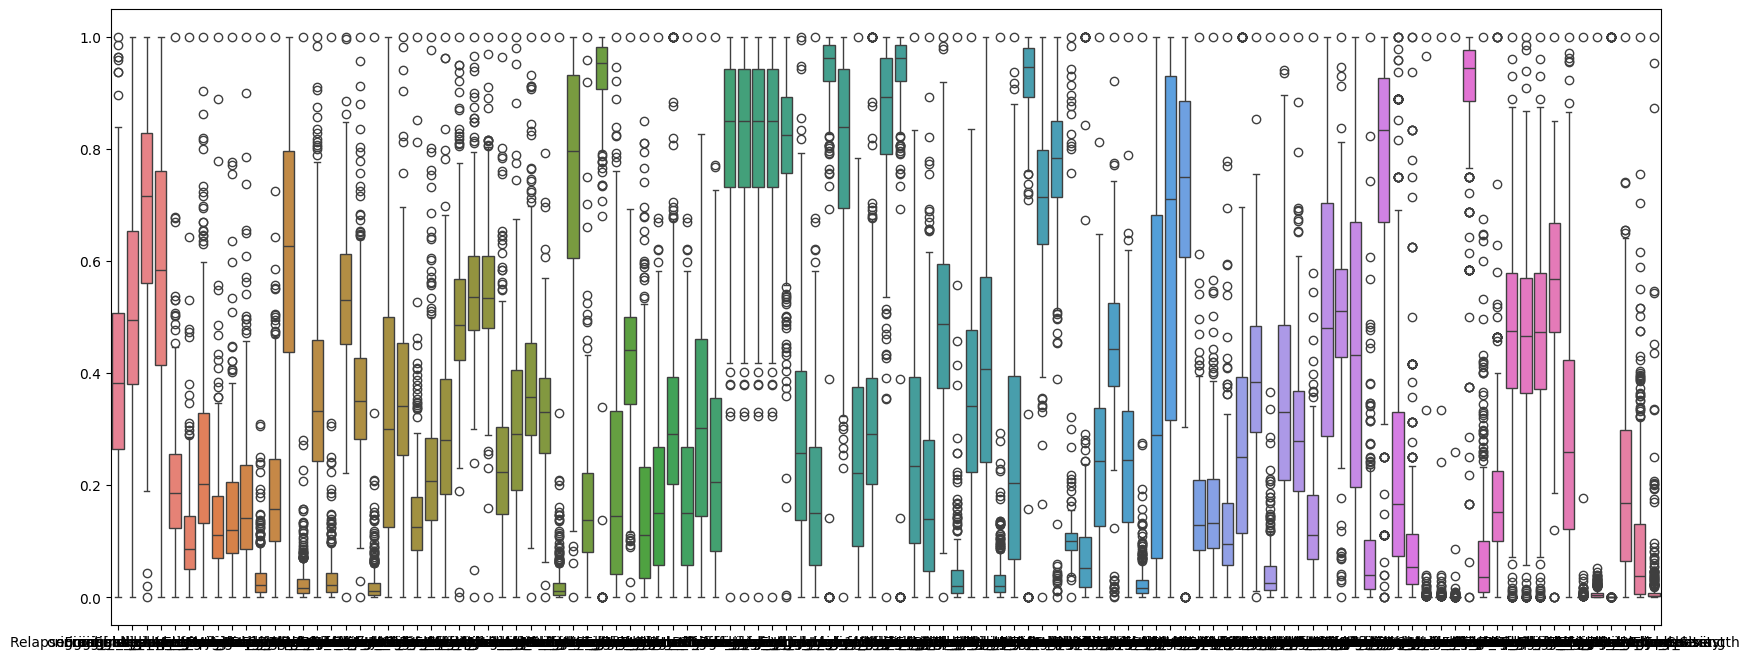

In [144]:
# 3. Normalisation
    # Minmax
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
dataset[dataset.select_dtypes(np.float64).columns] = scaler.fit_transform(dataset[dataset.select_dtypes(np.float64).columns])
dataset[dataset.select_dtypes(np.float64).columns]

import seaborn as sns

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data=dataset[dataset.select_dtypes(np.float64).columns],ax=ax)